# 5. Aplicación sobre el inventario de la Alta Guajira

Este notebook aplica el modelo final a las 120 estructuras de la Alta Guajira y produce la **matriz de priorización**: la tabla que las ordena según su afinidad con la clase H2 (la *Sub-Circular Depression*, SCD) y les asigna una franja de prioridad alta, media o baja.

Se usa el modelo exactamente como quedó congelado y evaluado en el notebook 4, sin reentrenarlo, y con los cortes de las franjas que se fijaron allí antes de mirar estas imágenes. Nada de lo que se observe aquí cambia el modelo, la calibración ni los cortes. Las 120 estructuras se clasificaron antes como posibles SCD solo por interpretación visual; no son una verdad de campo, así que aquí no hay aciertos ni errores que medir. Lo que se obtiene es un **orden de prioridad**, y cada resultado es una predicción del modelo que queda por confirmar en campo.

1. **Configuración** y verificación de que el modelo es el mismo que se evaluó en el **holdout** (las 101 imágenes que se apartaron en el notebook 1 y se usaron una sola vez, en el notebook 4, para medir el desempeño con imágenes nuevas).
2. **El inventario:** qué imágenes son, dónde están y con qué zoom se capturaron, comparado con las del entrenamiento.
3. **Independencia:** si alguna de las 120 comparte terreno con una imagen de entrenamiento.
4. **Predicción:** una sola pasada del modelo.
5. **Distribución de los resultados.**
6. **Matriz de priorización**, en tabla, en mapa y en archivos para abrir en un sistema de información geográfica (SIG).
7. **Mapas de calor** de las estructuras con mayor prioridad.

Además de `dataset/` y `salidas/`, este notebook necesita la carpeta `dataset_aplicacion/`, con las 120 imágenes en `Candidata/` y su archivo de coordenadas.

## 5.1 Configuración

Las rutas son las de los notebooks anteriores más `APLICACION_DIR`, la carpeta del inventario. En Colab, `CARPETA_DRIVE` indica la carpeta de Google Drive que contiene `dataset/`, `dataset_aplicacion/` y `salidas/`; al ejecutar, Colab pide autorización para acceder a Drive y se ubica allí.

El notebook no entrena nada: lee de `salidas/` el modelo final y los cortes de las franjas, que escribió el notebook 4, las predicciones de validación cruzada del notebook 3, con las que se recuerda en la sección 5.1 cómo se comportan las franjas, y la partición del notebook 1, que se usa en la sección 5.3 para conocer la posición de las imágenes de entrenamiento. Antes de usar la partición se comprueba su hash, como en los notebooks anteriores.

Entrenar en una tarjeta gráfica no da exactamente los mismos pesos en dos máquinas distintas, así que este notebook no puede reconstruir el modelo: tiene que usar el archivo guardado. Para asegurar que ese archivo es el mismo modelo que se evaluó en el holdout se compara su **huella**, un código SHA-256 calculado a partir de todos sus pesos (sección 4.2; un SHA-256 es un resumen que cambia por completo si cambia un solo dato), con la que el notebook 4 registró en `salidas/resumen_interpretaciones.json` al evaluar el holdout. Si un solo peso fuera distinto, la huella cambiaría por completo y el notebook se detendría. Si los notebooks se ejecutan desde cero en otra máquina, el modelo final será otro, con otra huella, pero el notebook 4 registrará esa nueva huella y la comprobación seguirá exigiendo lo mismo: que el modelo aplicado sea el que se evaluó.

In [1]:
%pip install -q ultralytics==8.3.203

from pathlib import Path
import os, sys
import hashlib, json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
from IPython.display import display

CARPETA_DRIVE = "MyDrive/Geologia_SCD"   # carpeta del proyecto en Google Drive (con dataset/, dataset_aplicacion/ y salidas/)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(f"/content/drive/{CARPETA_DRIVE}")

DATASET_DIR = Path("dataset")
APLICACION_DIR = Path("dataset_aplicacion")
OUT_DIR = Path("salidas")

ESCALA_CAPTURA = 2       # 5.2: factor de escala con que se descargaron las imágenes, el mismo de las 600
IMGSZ, LADO_CACHE = 224, 448
R_CENTRO = 0.30          # 5.7: radio del disco central, en fracción del lado (el de la sección 4.7)
N_MAPAS_CALOR = 12       # 5.7: estructuras de mayor prioridad con mapa de calor

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

for archivo, notebook in [("particion.csv", "01_particion"), ("particion.hash", "01_particion"),
                          ("modelo_final.pt", "04_interpretaciones"), ("umbrales_prioridad.json", "04_interpretaciones"),
                          ("resumen_interpretaciones.json", "04_interpretaciones"), ("oof_predicciones.csv", "03_modelamiento")]:
    assert (OUT_DIR / archivo).exists(), f"Falta salidas/{archivo}: ejecuta antes {notebook}.ipynb."

def hash_particion(d):
    # misma definición que en el notebook 1
    cols = ["id", "clase", "grupo_particion", "split", "fold_val"]
    texto = d[cols].sort_values("id").to_csv(sep=";", index=False, lineterminator="\n", na_rep="")
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

part = pd.read_csv(OUT_DIR / "particion.csv", sep=";", encoding="utf-8-sig", dtype={"fold_val": "Int64"})
assert hash_particion(part) == (OUT_DIR / "particion.hash").read_text().strip(), "particion.csv fue modificado; vuelve a ejecutar el notebook 1."

resumen_nb4 = json.loads((OUT_DIR / "resumen_interpretaciones.json").read_text(encoding="utf-8"))
assert resumen_nb4["particion_hash"] == hash_particion(part), "Los resultados del notebook 4 son de otra partición; vuelve a ejecutarlo."
umbrales = json.loads((OUT_DIR / "umbrales_prioridad.json").read_text(encoding="utf-8"))
T_OPT, T_ALTA, T_MEDIA = umbrales["temperatura"], umbrales["p_h2_franja_alta_desde"], umbrales["p_h2_franja_media_desde"]
print("Partición verificada.")
print("Dispositivo:", torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "CPU")

Mounted at /content/drive
Partición verificada.
Dispositivo: Tesla T4


In [2]:
#@title Funciones de apoyo (se pueden dejar plegadas)

R_MERCATOR = 6378137.0            # radio de la esfera de Web Mercator (m)
METROS_PX_ZOOM0 = 156543.03392    # metros por píxel del zoom 0 en el ecuador
MAPA_TIERRA = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_land.geojson"
COLOR_FRANJA = {"alta": "#C44E52", "media": "#DD8452", "baja": "#8C8C8C"}

# ---------- Coordenadas y huellas (igual que en el notebook 1) ----------
def sha256_de(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 16), b""):
            h.update(bloque)
    return h.hexdigest()

def a_lat_lon(x, y):
    lon = np.degrees(np.asarray(x, float) / R_MERCATOR)
    lat = np.degrees(2 * np.arctan(np.exp(np.asarray(y, float) / R_MERCATOR)) - np.pi / 2)
    return lat, lon

def lado_huella_plano(zoom, tam_px):
    """Lado de la huella en el plano de Web Mercator (m), comparable con X_3857 e Y_3857."""
    return (tam_px / ESCALA_CAPTURA) * METROS_PX_ZOOM0 / 2.0 ** np.asarray(zoom, float)

def huellas_cruzadas(x1, y1, lado1, x2, y2, lado2):
    """Matriz booleana: True si la huella i del primer grupo se cruza con la huella j del segundo."""
    suma = (lado1[:, None] + lado2[None, :]) / 2
    return (np.abs(x1[:, None] - x2[None, :]) < suma) & (np.abs(y1[:, None] - y2[None, :]) < suma)

def haversine_km(lat1, lon1, lat2, lon2):
    a, b = np.radians(lat1)[:, None], np.radians(lat2)[None, :]
    dlat, dlon = b - a, np.radians(lon2)[None, :] - np.radians(lon1)[:, None]
    h = np.sin(dlat / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

# ---------- Modelo (el mismo preprocesamiento que en los notebooks 3 y 4) ----------
def cargar_reducida(ruta):
    with Image.open(ruta) as im:
        return im.convert("RGB").resize((LADO_CACHE, LADO_CACHE), Image.LANCZOS)

TRANSFORMACION = T.Compose([T.Resize(IMGSZ), T.ToTensor()])   # YOLO recibe los píxeles entre 0 y 1, sin otra normalización

def cargar_modelo(ruta):
    from ultralytics import YOLO
    from ultralytics.nn.tasks import ClassificationModel
    guardado = torch.load(ruta, map_location="cpu", weights_only=True)
    red = YOLO(f"{guardado['variante']}.pt").model.float()
    ClassificationModel.reshape_outputs(red, len(guardado["clases"]))
    red.load_state_dict(guardado["state_dict"])
    for p in red.parameters():
        p.requires_grad_(True)       # hace falta para los mapas de calor
    return red.to(DISPOSITIVO).eval(), guardado["variante"], guardado["clases"]

def huella(red):
    h = hashlib.sha256()
    for nombre, valor in sorted(red.state_dict().items()):
        h.update(nombre.encode()); h.update(valor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

def logits_de(red, x):
    salida = red(x)
    return salida[1] if isinstance(salida, (tuple, list)) else salida

@torch.no_grad()
def probabilidades(red, imagenes, lote=32):
    salida = []
    for i in range(0, len(imagenes), lote):
        x = torch.stack([TRANSFORMACION(im) for im in imagenes[i:i + lote]]).to(DISPOSITIVO)
        salida.append(torch.softmax(logits_de(red, x), dim=1).cpu().numpy())
    return np.concatenate(salida)

def escalar(p, T_):
    """Aplica la temperatura T_ a una matriz de probabilidades."""
    z = np.log(np.clip(p, 1e-12, 1.0)) / T_
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def franja(p):
    return np.where(p >= T_ALTA, "alta", np.where(p >= T_MEDIA, "media", "baja"))

def gradcam(red, imagenes, clase):
    """Mapa de calor de la clase indicada, sobre el último bloque convolucional (como en la sección 4.7)."""
    capa = red.model[-2]
    guardado = {}
    gancho = capa.register_forward_hook(lambda m, i, o: guardado.__setitem__("act", o))
    x = torch.stack([TRANSFORMACION(im) for im in imagenes]).to(DISPOSITIVO)
    with torch.enable_grad():
        logits = logits_de(red, x)
        grad = torch.autograd.grad(logits[:, clase].sum(), guardado["act"])[0]
    gancho.remove()
    cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * guardado["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMGSZ, IMGSZ), mode="bilinear", align_corners=False)[:, 0].detach().cpu().numpy()
    return cam / np.maximum(cam.max(axis=(1, 2), keepdims=True), 1e-12)

# ---------- Mapas ----------
TIERRA = None
def fondo_guajira(ax, lat, lon, margen=0.08):
    """Línea de costa (Natural Earth 1:10 millones) alrededor de los puntos dados."""
    global TIERRA
    if TIERRA is None:
        TIERRA = gpd.read_file(MAPA_TIERRA)
    ax.set_facecolor("#e3eef5")
    TIERRA.plot(ax=ax, color="#ece6d6", edgecolor="#9a9a8a", linewidth=0.6, zorder=0)
    ax.set_xlim(np.min(lon) - margen, np.max(lon) + margen); ax.set_ylim(np.min(lat) - margen, np.max(lat) + margen)
    ax.set_aspect(1 / np.cos(np.radians(np.mean(lat))))
    ax.set_xlabel("longitud"); ax.set_ylabel("latitud")

### El modelo final

Se carga `salidas/modelo_final.pt`, se calcula su huella y se compara con la registrada. El archivo guarda también qué variante es (YOLOv8n-cls, elegida en el notebook 3) y el orden de las 10 clases.

Junto al modelo se leen los dos valores que el notebook 4 dejó en `salidas/umbrales_prioridad.json`:

- La **temperatura** `T` (sección 4.3). El modelo reparte entre las 10 clases unas probabilidades que suman 1; la temperatura las corrige para que se puedan leer como probabilidades reales (una P(H2) de 0,8 debería ser H2 unas 8 de cada 10 veces). Aquí T = 1,03, casi 1: la corrección es mínima.
- Los dos **cortes de las franjas de prioridad** (sección 4.8), sobre la probabilidad calibrada de H2, que se escribe **P(H2)**. Se explican en el apartado siguiente.

In [3]:
MODELO, VARIANTE, CLASES = cargar_modelo(OUT_DIR / "modelo_final.pt")
IDX = {c: i for i, c in enumerate(CLASES)}
HUELLA = huella(MODELO)
assert HUELLA == resumen_nb4["huella_modelo_final"], "salidas/modelo_final.pt no es el modelo evaluado en el holdout; vuelve a ejecutar el notebook 4."
print(f"Modelo: {VARIANTE}. Huella verificada: {HUELLA[:12]}…")
print(f"Temperatura: {T_OPT:.3f}")
print(f"Franja alta: P(H2) ≥ {T_ALTA:.3f}.  Franja media: {T_MEDIA:.3f} ≤ P(H2) < {T_ALTA:.3f}.  Franja baja: P(H2) < {T_MEDIA:.3f}.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Modelo: yolov8n-cls. Huella verificada: d4e7b2a070a5…
Temperatura: 1.027
Franja alta: P(H2) ≥ 0.710.  Franja media: 0.092 ≤ P(H2) < 0.710.  Franja baja: P(H2) < 0.092.


### Las franjas de prioridad y de dónde salen sus cortes

Las 120 estructuras se reparten en tres franjas según su P(H2). Los dos cortes no se eligieron a mano ni mirando estas imágenes: se fijaron en la sección 4.8 sobre la **curva de precisión y recall** de H2 (sección 3.5), con las predicciones de **validación cruzada** del notebook 3: cada una de las 499 imágenes de **desarrollo** (las 600 menos las 101 del holdout) se predijo con un modelo que no la había visto al entrenar. Fijarlos después de ver las 120 permitiría acomodarlos al resultado y le quitaría a esta aplicación su carácter de prueba externa. Cada corte responde a una pregunta distinta:

- **Franja alta, desde P(H2) = 0,710: un criterio de precisión.** La **precisión** es la fracción de las imágenes marcadas que de verdad son H2. El corte es el menor valor de P(H2) a partir del cual la precisión es de al menos el 90 % y ya no baja de ese valor en ningún corte superior. Responde a la pregunta «¿desde dónde puedo confiar en que casi todo lo que marco es H2?».
- **Franja media, de 0,092 a 0,710: un criterio de recall.** El **recall** es la fracción de las H2 que se recuperan. El corte inferior es el mayor valor de P(H2) con el que las franjas alta y media juntas todavía recuperan al menos el 90 % de las H2. Responde a la pregunta «¿hasta dónde tengo que bajar para no dejar atrás casi ninguna H2?». La franja media es, por tanto, lo que hay que añadir a la alta para no perder H2, aunque ya no cumpla la precisión del 90 %.
- **Franja baja, por debajo de 0,092:** donde en el desarrollo quedaba como mucho una de cada diez H2.

**Por qué 90 %.** Es una convención decidida antes de calcular los cortes, no un valor que salga de los datos. En la franja alta se acepta como mucho una falsa alarma por cada diez estructuras, y entre las franjas alta y media se acepta dejar escapar como mucho una H2 de cada diez. Un criterio más exigente dejaría la franja alta casi vacía y la media muy grande; uno más laxo llenaría la alta de falsas alarmas y dejaría escapar más H2.

**Por qué «ya no baja».** La precisión no crece de forma ordenada al subir el corte. Con valores altos de P(H2) quedan pocas imágenes, y una sola de otra clase la hace bajar y volver a subir. Exigir que se mantenga por encima del 90 % en todos los cortes superiores evita que el corte caiga en un punto que cumple el criterio por azar.

La tabla recalcula, con las predicciones de validación cruzada del notebook 3 y la temperatura del notebook 4, cómo se repartían las imágenes de desarrollo en las tres franjas: cuántas H2 y cuántas de otras clases había en cada una, qué proporción eran H2 y qué fracción de todas las H2 se había recuperado al llegar a cada franja.

In [4]:
ORDEN_FRANJAS = ["alta", "media", "baja"]
oof = pd.read_csv(OUT_DIR / "oof_predicciones.csv", sep=";", encoding="utf-8-sig")
oof = oof[oof["modelo"] == VARIANTE]
p_dev = escalar(oof[[f"prob_{c}" for c in CLASES]].to_numpy(), T_OPT)[:, IDX["H2"]]
es_h2_dev, franja_dev = (oof["clase"] == "H2").to_numpy(), franja(p_dev)

desarrollo = pd.DataFrame({"H2": [int((es_h2_dev & (franja_dev == b)).sum()) for b in ORDEN_FRANJAS],
                           "otras clases": [int((~es_h2_dev & (franja_dev == b)).sum()) for b in ORDEN_FRANJAS]},
                          index=[f"franja {b}" for b in ORDEN_FRANJAS])
desarrollo["proporción de H2"] = (desarrollo["H2"] / (desarrollo["H2"] + desarrollo["otras clases"])).round(2)
desarrollo["H2 recuperadas hasta esta franja"] = (desarrollo["H2"].cumsum() / es_h2_dev.sum()).round(2)
display(desarrollo)
print(f"{len(oof)} imágenes de validación cruzada, {es_h2_dev.sum()} de ellas H2. "
      f"Entre los dos cortes caen {int((franja_dev == 'media').sum())} imágenes.")

,H2,otras clases,proporción de H2,H2 recuperadas hasta esta franja
franja alta,38,4,0.90,0.76
franja media,7,17,0.29,0.90
franja baja,5,428,0.01,1.00


499 imágenes de validación cruzada, 50 de ellas H2. Entre los dos cortes caen 24 imágenes.


En el desarrollo, la franja alta reunió 38 H2 y 4 imágenes de otras clases: una proporción de H2 de 0,90, justo el criterio. La franja media tuvo 7 H2 y 17 de otras clases, unas 3 H2 de cada 10. Con ella, las H2 recuperadas pasan del 76 % al 90 % (45 de 50). La franja baja dejó fuera 5 H2 entre 433 imágenes.

La franja media es ancha, de 0,092 a 0,710, pero en el desarrollo contenía pocas imágenes: solo 24 de 499. La P(H2) del modelo es casi binaria, y la mayoría de las imágenes queda cerca de 0 o de 1 (sección 4.3). Las pocas H2 que el modelo duda en reconocer se reparten por toda esa zona, y por eso el corte inferior tuvo que bajar hasta 0,092 para recuperarlas. Dentro de la franja media, una P(H2) de 0,4 no significa «40 % de probabilidad»: en esa zona había tan pocas imágenes que la calibración no se pudo comprobar. Se lee como zona de duda.

Al aplicar estas franjas a La Guajira hay que tener presentes dos cosas. Las proporciones de la tabla se midieron en un conjunto donde 1 de cada 10 imágenes era H2. En el inventario esa proporción es desconocida y probablemente mayor, porque las 120 se preseleccionaron como posibles SCD, así que las franjas las definen los cortes y no esos porcentajes. Además, la franja media es la que más importa fuera de las regiones conocidas: en el ensayo de región nueva (sección 4.9), recogió 18 de las 37 H2 de las regiones que el modelo sí aprende. Una campaña que visitara solo la franja alta habría dejado fuera casi la mitad.

## 5.2 El inventario

El inventario tiene el mismo formato que el dataset de entrenamiento: una imagen PNG por estructura en `dataset_aplicacion/Candidata/` y un CSV con su número (`id`), la posición de su centro y el nivel de zoom. Antes de usarlas se comprueba que cada fila tiene su imagen, que no sobran imágenes, que todas miden lo mismo y que ninguna está repetida. Para lo último se compara el contenido con un **SHA-256**, un código que es idéntico para dos archivos iguales y completamente distinto si cambia un solo píxel; el mismo código permite comprobar que ninguna de las 120 es una de las 600 imágenes de entrenamiento.

Para comparar el inventario con el entrenamiento se usan las mismas magnitudes del notebook 1:

- **Coordenadas.** `X_3857` e `Y_3857` son la posición del centro en metros sobre el plano de los mapas web (*Web Mercator*); se convierten a latitud y longitud.
- **Zoom.** En un mapa web cada nivel de zoom duplica el detalle. Es importante porque la misma geoforma se ve muy distinta con dos zooms diferentes, y el modelo aprendió cada clase con los zooms de sus imágenes.
- **Resolución (GSD).** Cuántos metros de terreno cubre un píxel del nivel de zoom: `156543,03 · cos(latitud) / 2^zoom`. Es el valor nominal; con factor de escala 2, cada píxel de la imágen cubre la mitad, como se explicó en el notebook 2.
- **Huella.** El cuadrado de terreno que abarca la imagen. Las imágenes se descargaron con factor de escala 2 (cada píxel cubre medio píxel de zoom) y se recortaron a 1184 × 1184, así que su lado es `(1184 / 2) · 156543,03 / 2^zoom` en el plano del mapa, y por `cos(latitud)` en metros de terreno. (Es la huella de la imagen sobre el terreno, que no tiene nada que ver con la huella de los pesos del modelo de la sección 5.1.)

El modelo nunca vio una H2 de La Guajira. Las imágenes de entrenamiento que más se parecen a estas por lugar son los 60 **Jagüeyes** (estanques excavados para acumular agua de lluvia, típicos de La Guajira), todos de la Alta Guajira, así que la comparación se hace contra ellos y contra las 60 H2.

In [5]:
apl = pd.read_csv(next(APLICACION_DIR.glob("*.csv")), sep=";", decimal=",", encoding="utf-8-sig")
apl = apl[["id", "clase", "X_3857", "Y_3857", "zoom"]].sort_values("id").reset_index(drop=True)
apl["ruta"] = [APLICACION_DIR / c / f"{i}.png" for c, i in zip(apl["clase"], apl["id"])]

en_disco = {p for c in apl["clase"].unique() for p in (APLICACION_DIR / c).glob("*.png")}
tamanos = {}
for r in apl["ruta"]:
    if r.exists():
        with Image.open(r) as im:
            tamanos[im.size] = tamanos.get(im.size, 0) + 1
apl["sha256"] = [sha256_de(r) if r.exists() else None for r in apl["ruta"]]
comprobaciones = {
    "ids únicos en el CSV": apl["id"].is_unique,
    "cada fila tiene su imagen": apl["ruta"].map(Path.exists).all(),
    "no sobran imágenes en la carpeta": en_disco == set(apl["ruta"]),
    "todas las imágenes miden lo mismo": len(tamanos) == 1,
    "ninguna imagen repetida": not apl["sha256"].duplicated().any(),
    "ninguna es una imagen de entrenamiento": not apl["sha256"].isin(part["sha256"]).any(),
}
display(pd.Series(comprobaciones, name="se cumple").to_frame())
assert all(comprobaciones.values()), "El inventario no pasó las comprobaciones."
TAM_PX = next(iter(tamanos))[0]

apl["lat"], apl["lon"] = a_lat_lon(apl["X_3857"], apl["Y_3857"])
apl["gsd_m_px"] = METROS_PX_ZOOM0 * np.cos(np.radians(apl["lat"])) / 2.0 ** apl["zoom"]
apl["huella_lado_m"] = lado_huella_plano(apl["zoom"], TAM_PX) * np.cos(np.radians(apl["lat"]))
print(f"{len(apl)} estructuras, imágenes de {TAM_PX} × {TAM_PX} píxeles.")

grupos = {"120 de La Guajira": apl, "H2 (entrenamiento)": part[part["clase"] == "H2"], "Jagüey (entrenamiento)": part[part["clase"] == "Jaguey"]}
display(pd.DataFrame({n: {"imágenes": len(g), "zoom mínimo": g["zoom"].min(), "zoom máximo": g["zoom"].max(),
                          "GSD mediana (m/px)": g["gsd_m_px"].median(), "lado de huella mediano (m)": g["huella_lado_m"].median()}
                      for n, g in grupos.items()}).T.round(2))

,se cumple
ids únicos en el CSV,True
cada fila tiene su imagen,True
no sobran imágenes en la carpeta,True
todas las imágenes miden lo mismo,True
ninguna imagen repetida,True
ninguna es una imagen de entrenamiento,True


120 estructuras, imágenes de 1184 × 1184 píxeles.


,imágenes,zoom mínimo,zoom máximo,GSD mediana (m/px),lado de huella mediano (m)
120 de La Guajira,120.0,18.0,21.0,0.29,172.87
H2 (entrenamiento),60.0,15.0,19.0,0.75,443.51
Jagüey (entrenamiento),60.0,18.0,20.0,0.29,172.83


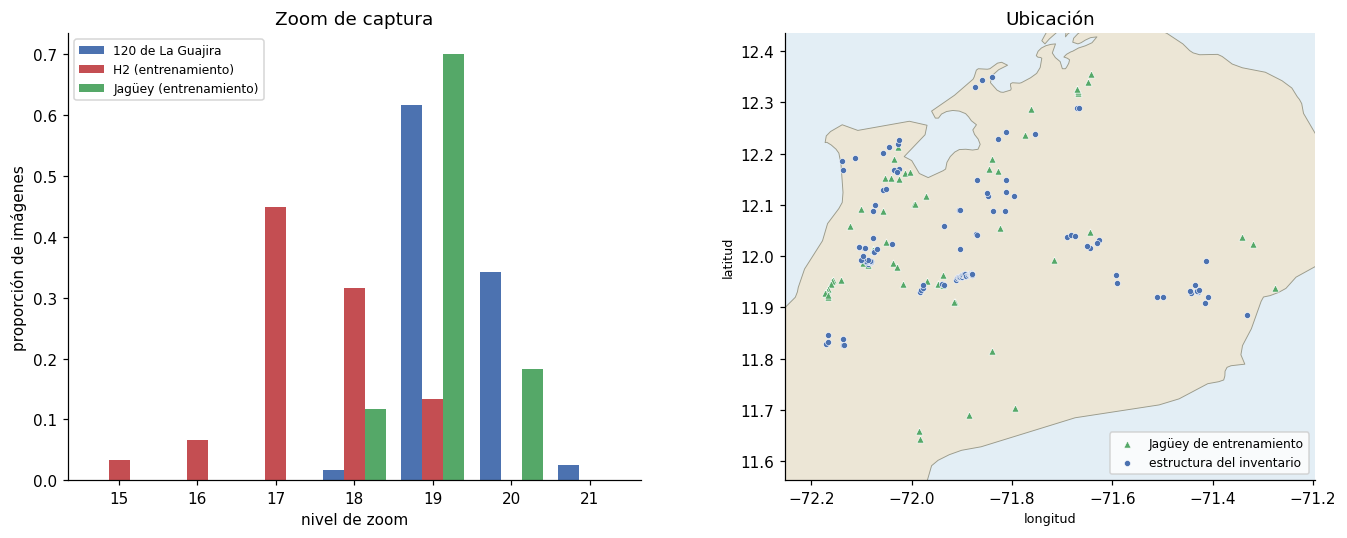

In [6]:
zooms = range(min(g["zoom"].min() for g in grupos.values()), max(g["zoom"].max() for g in grupos.values()) + 1)
reparto_zoom = pd.DataFrame({n: g["zoom"].value_counts(normalize=True).reindex(zooms, fill_value=0) for n, g in grupos.items()})

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
reparto_zoom.plot.bar(ax=ejes[0], color=["#4C72B0", "#C44E52", "#55A868"], width=0.8, rot=0)
ejes[0].set_xlabel("nivel de zoom"); ejes[0].set_ylabel("proporción de imágenes"); ejes[0].set_title("Zoom de captura")
ejes[0].legend(fontsize=8)

jag = grupos["Jagüey (entrenamiento)"]
fondo_guajira(ejes[1], np.r_[apl["lat"], jag["lat"]], np.r_[apl["lon"], jag["lon"]])
ejes[1].scatter(jag["lon"], jag["lat"], s=22, marker="^", color="#55A868", edgecolor="white", lw=0.4, label="Jagüey de entrenamiento")
ejes[1].scatter(apl["lon"], apl["lat"], s=16, color="#4C72B0", edgecolor="white", lw=0.4, label="estructura del inventario")
ejes[1].legend(fontsize=8, loc="lower right"); ejes[1].set_title("Ubicación")
fig.tight_layout()
plt.show()

Las 120 imágenes pasan todas las comprobaciones: miden 1184 × 1184 píxeles como las de entrenamiento, ninguna está repetida y ninguna es una de las 600.

Por zoom, el inventario se parece a los Jagüeyes y no a las H2. Se capturó entre los zooms 18 y 21, casi todo con 19 (74 estructuras) y 20 (41). Su resolución nominal mediana (0,29 m/px) y el lado mediano de su huella (173 m) coinciden con los de los Jagüeyes. Las H2 de entrenamiento se capturaron desde más lejos, sobre todo con zooms 17 y 18: 0,75 m/px nominales y 444 m de lado, unas 2,6 veces más terreno por lado. Ninguna H2 de entrenamiento tiene zoom 20 o 21, y 44 de las 120 sí lo tienen.

El mapa muestra que las 120 estructuras y los 60 Jagüeyes de entrenamiento ocupan la misma zona y están intercalados. Por lugar, paisaje y zoom, el modelo ve estas imágenes como vio los Jagüeyes. Al sesgo de paisaje medido en la sección 4.6 se suma este del zoom, y los dos empujan hacia Jagüey.

## 5.3 Independencia con el entrenamiento

La aplicación solo es una prueba externa si el modelo no vio antes el mismo terreno. Que ninguna de las 120 imágenes sea una de las 600 ya se comprobó; queda por ver si alguna **comparte terreno** con una imagen de entrenamiento aunque el archivo sea distinto, por ejemplo una estructura del inventario que esté dentro de la foto de un Jagüey. Se usa el mismo criterio de solape de huellas del notebook 1: dos imágenes comparten terreno si sus cuadrados se cruzan en el plano del mapa.

Las estructuras que se solapen no se excluyen: se marcan en la matriz final, porque su resultado puede estar influido por lo que el modelo aprendió de esa imagen. Se da además la distancia de cada estructura al Jagüey de entrenamiento más cercano. Como referencia, el notebook 1 consideraba del mismo sitio dos imágenes a menos de 1 km.

También se buscan solapes **entre las 120**: dos entradas del inventario cuyas huellas se cruzan pueden ser la misma estructura capturada dos veces, o dos estructuras vecinas.

Estructuras que comparten terreno con una imagen de entrenamiento: 1 de 120.


,id,zoom,huella_lado_m,solapa_con_entrenamiento,dist_jaguey_km
36,37,19,172.934,Jaguey 584,0.114


Pares de estructuras del inventario con huellas solapadas: 26.


,id,id solapado,distancia entre centros (m)
0,4,5,98.0
1,6,7,51.0
2,9,10,52.0
3,11,14,169.0
4,12,13,106.0
5,21,22,134.0
6,26,27,70.0
7,30,31,122.0
8,35,36,113.0
9,38,39,316.0


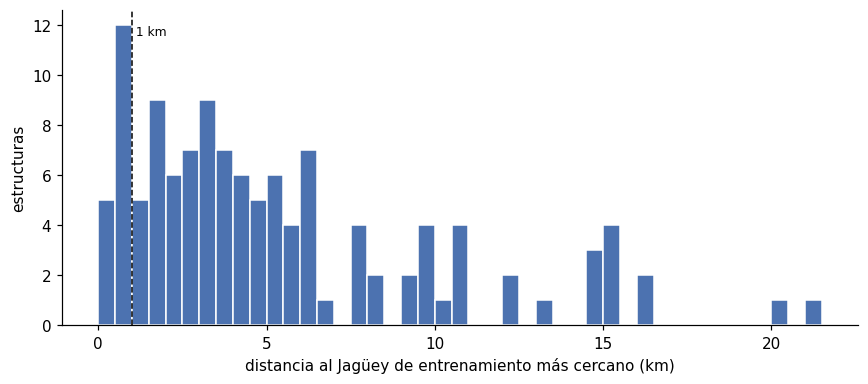

A menos de 1 km de un Jagüey de entrenamiento: 17 estructuras. Mediana de la distancia: 4.0 km.


In [7]:
lado_apl = lado_huella_plano(apl["zoom"], TAM_PX)
lado_ent = lado_huella_plano(part["zoom"], part["ancho"].to_numpy())
cruce = huellas_cruzadas(apl["X_3857"].to_numpy(), apl["Y_3857"].to_numpy(), lado_apl,
                         part["X_3857"].to_numpy(), part["Y_3857"].to_numpy(), lado_ent)
apl["solapa_con_entrenamiento"] = [", ".join(f"{part['clase'].iat[j]} {part['id'].iat[j]}" for j in np.flatnonzero(fila)) for fila in cruce]

distancias = haversine_km(apl["lat"].to_numpy(), apl["lon"].to_numpy(), part["lat"].to_numpy(), part["lon"].to_numpy())
apl["dist_jaguey_km"] = distancias[:, (part["clase"] == "Jaguey").to_numpy()].min(axis=1)

solapadas = apl[apl["solapa_con_entrenamiento"] != ""]
print(f"Estructuras que comparten terreno con una imagen de entrenamiento: {len(solapadas)} de {len(apl)}.")
display(solapadas[["id", "zoom", "huella_lado_m", "solapa_con_entrenamiento", "dist_jaguey_km"]].round(3))

entre_ellas = np.triu(huellas_cruzadas(apl["X_3857"].to_numpy(), apl["Y_3857"].to_numpy(), lado_apl,
                                       apl["X_3857"].to_numpy(), apl["Y_3857"].to_numpy(), lado_apl), k=1)
pares = [(int(apl["id"].iat[i]), int(apl["id"].iat[j])) for i, j in zip(*np.nonzero(entre_ellas))]
d_pares = [haversine_km(apl["lat"].to_numpy()[[i]], apl["lon"].to_numpy()[[i]], apl["lat"].to_numpy()[[j]], apl["lon"].to_numpy()[[j]])[0, 0] * 1000
           for i, j in zip(*np.nonzero(entre_ellas))]
print(f"Pares de estructuras del inventario con huellas solapadas: {len(pares)}.")
if pares:
    display(pd.DataFrame(pares, columns=["id", "id solapado"]).assign(**{"distancia entre centros (m)": np.round(d_pares)}))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(apl["dist_jaguey_km"], bins=np.arange(0, apl["dist_jaguey_km"].max() + 0.5, 0.5), color="#4C72B0", edgecolor="white")
ax.axvline(1, color="black", ls="--", lw=1); ax.text(1, ax.get_ylim()[1] * 0.92, " 1 km", fontsize=8)
ax.set_xlabel("distancia al Jagüey de entrenamiento más cercano (km)"); ax.set_ylabel("estructuras")
fig.tight_layout()
plt.show()
print(f"A menos de 1 km de un Jagüey de entrenamiento: {(apl['dist_jaguey_km'] < 1).sum()} estructuras. Mediana de la distancia: {apl['dist_jaguey_km'].median():.1f} km.")

Solo la estructura 37 comparte terreno con una imagen de entrenamiento: su huella se cruza con la del Jagüey 584, cuyo centro está a 114 m. Queda marcada en la matriz. Las otras 119 no comparten terreno con ninguna de las 600, así que para ellas la aplicación es una prueba externa en sentido estricto.

No comparten terreno, pero sí paisaje: 17 estructuras están a menos de 1 km de un Jagüey de entrenamiento y la mitad a menos de 4,0 km. Es la situación que se ensayó con los montajes de la sección 4.6.

Entre las propias 120 hay 26 pares de huellas solapadas, con centros a entre 35 y 316 m. La mayoría son estructuras vecinas de un mismo campo. En los pares más cercanos las dos fotos muestran casi el mismo terreno: las 58 y 59, a 35 m, son prácticamente la misma escena desplazada. Sus resultados se comparan en la sección 5.6.

## 5.4 Predicción

Cada imagen se reduce como en el entrenamiento (primero a 448 píxeles y luego a 224, el tamaño de entrada de la red) y el modelo la procesa una sola vez, sin aumentos ni giros. Para cada estructura se conservan las 10 probabilidades, no solo la de H2: cuando P(H2) es baja o intermedia, interesa saber a qué otra geoforma se parece.

Las probabilidades sin calibrar se guardan en `salidas/aplicacion_predicciones.csv`; si el archivo ya existe se leen de ahí, igual que las del holdout en el notebook 4. La temperatura se aplica después.

In [8]:
IMAGENES = {int(i): cargar_reducida(r) for i, r in zip(apl["id"], apl["ruta"])}
COLS_PROB = [f"prob_{c}" for c in CLASES]

ruta_pred = OUT_DIR / "aplicacion_predicciones.csv"
if ruta_pred.exists():
    pred = pd.read_csv(ruta_pred, sep=";", encoding="utf-8-sig")
    assert pred["id"].tolist() == apl["id"].tolist(), "aplicacion_predicciones.csv no corresponde a este inventario."
else:
    prob = probabilidades(MODELO, [IMAGENES[int(i)] for i in apl["id"]])
    pred = pd.concat([apl[["id"]], pd.DataFrame(prob, columns=COLS_PROB)], axis=1)
    pred.to_csv(ruta_pred, sep=";", index=False, encoding="utf-8-sig")

P_CAL = escalar(pred[COLS_PROB].to_numpy(), T_OPT)
print(f"{len(pred)} estructuras con sus 10 probabilidades. Suma de cada fila tras calibrar: entre {P_CAL.sum(1).min():.4f} y {P_CAL.sum(1).max():.4f}.")

120 estructuras con sus 10 probabilidades. Suma de cada fila tras calibrar: entre 1.0000 y 1.0000.


## 5.5 Cómo se reparten los resultados

Con las probabilidades calibradas se calcula, para cada estructura:

- **P(H2)** y su **franja** (alta, media o baja), según los cortes de la sección 5.1.
- La **clase predicha**: la de mayor probabilidad entre las 10 (las diez clases se describen al comienzo del notebook 1).
- La **clase alternativa**: la más probable sin contar H2. Si la estructura no es una SCD, es la geoforma que el modelo considera más parecida. Cuando la clase predicha no es H2, coincide con ella.

En el notebook 4 se midieron dos efectos que hay que tener presentes al leer estas cifras. En la sección 4.6, una H2 montada sobre paisaje guajiro solo se reconocía como H2 en un tercio de los casos y en la mitad pasaba a Jagüey. En la sección 4.9, las H2 de una región que el modelo no había visto se reconocían menos de la mitad de las veces, aunque casi todas seguían en las franjas alta o media. Por eso se espera que muchas estructuras salgan como Jagüey y que P(H2) sea, en general, más baja que la de las H2 de entrenamiento. Una predicción de Jagüey no descarta una SCD.

Las figuras muestran la distribución de P(H2) con los dos cortes, cuántas estructuras caen en cada franja y la relación entre P(H2) y P(Jagüey), que son las dos clases que compiten en La Guajira.

franja,alta,media,baja
estructuras,30,30,60


,count,mean,std,min,10%,25%,50%,75%,90%,max
P(H2),120.0,0.341,0.383,0.0,0.001,0.004,0.123,0.719,0.953,0.997


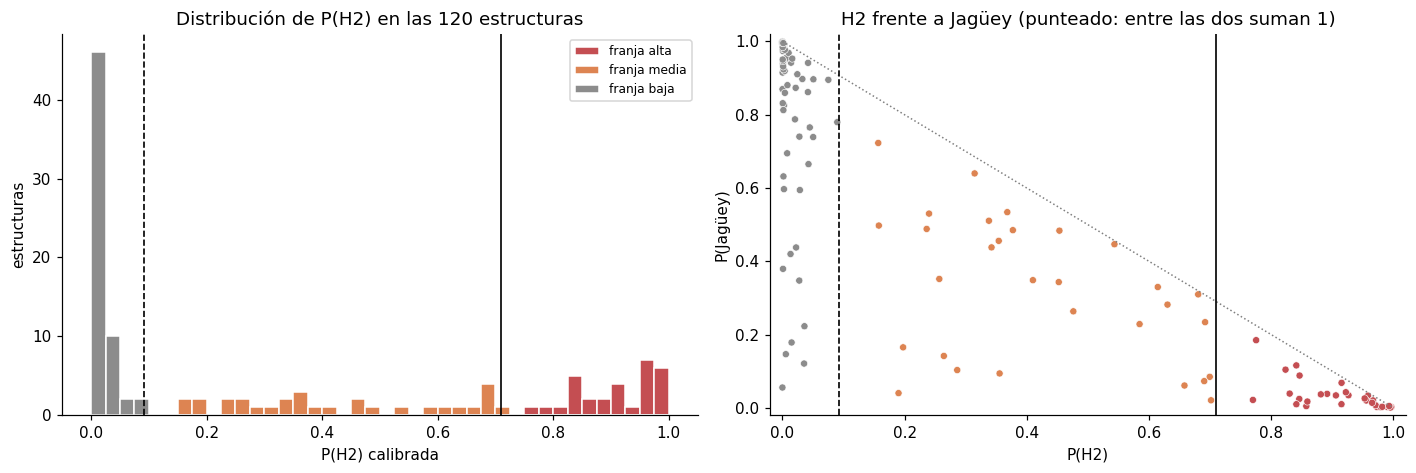

In [9]:
res = apl[["id", "lat", "lon", "zoom", "solapa_con_entrenamiento", "dist_jaguey_km"]].copy()
res["P(H2)"] = P_CAL[:, IDX["H2"]]
res["P(Jagüey)"] = P_CAL[:, IDX["Jaguey"]]
res["franja"] = franja(res["P(H2)"].to_numpy())
res["clase predicha"] = [CLASES[j] for j in P_CAL.argmax(1)]
sin_h2 = P_CAL.copy(); sin_h2[:, IDX["H2"]] = -1
res["clase alternativa"] = [CLASES[j] for j in sin_h2.argmax(1)]
res["P(alternativa)"] = sin_h2.max(1)

display(res["franja"].value_counts().reindex(ORDEN_FRANJAS, fill_value=0).rename("estructuras").to_frame().T)
display(res["P(H2)"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3).rename("P(H2)").to_frame().T)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
bordes = np.linspace(0, 1, 41)
for f in ORDEN_FRANJAS:
    ejes[0].hist(res.loc[res["franja"] == f, "P(H2)"], bins=bordes, color=COLOR_FRANJA[f], edgecolor="white", label=f"franja {f}")
for t, estilo in [(T_ALTA, "-"), (T_MEDIA, "--")]:
    ejes[0].axvline(t, color="black", lw=1.1, ls=estilo)
ejes[0].set_xlabel("P(H2) calibrada"); ejes[0].set_ylabel("estructuras"); ejes[0].legend(fontsize=8)
ejes[0].set_title("Distribución de P(H2) en las 120 estructuras")

ejes[1].scatter(res["P(H2)"], res["P(Jagüey)"], c=res["franja"].map(COLOR_FRANJA), s=22, edgecolor="white", lw=0.4)
ejes[1].plot([0, 1], [1, 0], color="gray", ls=":", lw=1)
for t, estilo in [(T_ALTA, "-"), (T_MEDIA, "--")]:
    ejes[1].axvline(t, color="black", lw=1.1, ls=estilo)
ejes[1].set_xlabel("P(H2)"); ejes[1].set_ylabel("P(Jagüey)"); ejes[1].set_xlim(-0.02, 1.02); ejes[1].set_ylim(-0.02, 1.02)
ejes[1].set_title("H2 frente a Jagüey (punteado: entre las dos suman 1)")
fig.tight_layout()
plt.show()

De las 120 estructuras, 30 quedan en la franja alta, 30 en la media y 60 en la baja. P(H2) se reparte en dos grupos. En un cuarto del inventario es menor que 0,004, y en otro cuarto supera 0,71. La mediana es 0,123.

El resultado es menos extremo de lo que hacían temer las secciones 4.6 y 4.9. A pesar del sesgo hacia Jagüey, una de cada cuatro estructuras alcanza la franja alta: en ellas el modelo encuentra lo que en el entrenamiento distinguía a las H2. Aun así, la proporción de H2 verdaderas dentro de esa franja no se puede trasladar del desarrollo. Allí, 9 de cada 10 imágenes de la franja alta eran H2, pero en una región nueva el modelo es menos fiable (sección 4.9). Aquí la franja sirve para ordenar las estructuras; cuántas de la franja alta son SCD solo lo dirá el campo.

En la figura de la derecha, las estructuras de la franja alta quedan sobre la línea punteada: entre H2 y Jagüey reúnen casi toda la probabilidad. En la franja baja la mayoría está cerca de la línea, con P(Jagüey) alta, pero una de cada cuatro queda bastante por debajo: son las que el modelo asigna a otra geoforma, como Impact crater o Thermokarst. Las de la franja media quedan casi todas por debajo, porque otras clases toman parte de la probabilidad. Es la zona en la que el modelo duda.

### Franja frente a clase predicha y clase alternativa

La tabla cruza la franja con la clase predicha: dice, por ejemplo, cuántas estructuras de la franja media salieron como Jagüey y cuántas como otra geoforma. La segunda tabla hace lo mismo con la clase alternativa, que muestra con qué se confundiría cada estructura si no fuera una SCD.

In [10]:
def cruce_con_total(columna):
    t = pd.crosstab(res["franja"], res[columna]).reindex(ORDEN_FRANJAS, fill_value=0)
    t = t[t.sum().sort_values(ascending=False).index]
    t["total"] = t.sum(axis=1)
    t.loc["total"] = t.sum()
    return t

print("Franja frente a clase predicha")
display(cruce_con_total("clase predicha"))
print("Franja frente a clase alternativa (la más probable sin contar H2)")
display(cruce_con_total("clase alternativa"))

Franja frente a clase predicha


clase predicha,Jaguey,H2,Impact crater,Thermokarst,Flooded dune,Fairy circle,Karst,total
franja,,,,,,,,
alta,0,30,0,0,0,0,0,30
media,12,13,3,0,1,1,0,30
baja,51,0,5,2,1,0,1,60
total,63,43,8,2,2,1,1,120


Franja frente a clase alternativa (la más probable sin contar H2)


clase alternativa,Jaguey,Impact crater,Fairy circle,Flooded dune,Thermokarst,Karst,Salt lake,total
franja,,,,,,,,
alta,15,10,5,0,0,0,0,30
media,21,4,3,1,0,0,1,30
baja,51,5,0,1,2,1,0,60
total,87,19,8,2,2,1,1,120


Las 30 estructuras de la franja alta se predicen como H2. Su alternativa es Jagüey en 15, Impact crater en 10 y Fairy circle en 5. La franja media está partida: 13 estructuras se predicen como H2 aunque su P(H2) no llega al corte de la alta, 12 como Jagüey y 5 como otras geoformas. Esas 12 son el caso que advirtió la sección 4.6: el modelo las ve como Jagüey, pero con suficiente P(H2) para no descartarlas. En la franja baja, 51 de las 60 se predicen como Jagüey.

Como clase alternativa domina Jagüey (87 de 120), seguida de Impact crater (19). Es la misma confusión que apareció en el holdout y en la sección 4.9, donde las H2 de Brasil vistas como región nueva se fueron todas a Impact crater. Salt lake, Karst y Thermokarst casi no aparecen: para el modelo, el inventario no se parece a esas geoformas.

### El zoom de captura

La sección 5.2 mostró que el inventario se capturó con zooms más cercanos que las H2 de entrenamiento, que nunca tuvieron zoom 20 ni 21. La tabla cruza el zoom de cada estructura con su franja y da la P(H2) mediana por zoom.

In [11]:
por_zoom = pd.crosstab(res["zoom"], res["franja"]).reindex(columns=ORDEN_FRANJAS, fill_value=0)
por_zoom["P(H2) mediana"] = res.groupby("zoom")["P(H2)"].median().round(3)
display(por_zoom)

franja,alta,media,baja,P(H2) mediana
zoom,,,,
18,1,0,1,0.465
19,27,21,26,0.394
20,2,9,30,0.016
21,0,0,3,0.000


El zoom pesa mucho. De las 41 estructuras capturadas con zoom 20, 30 quedan en la franja baja, y su P(H2) mediana es 0,016. Con zoom 19 la mediana es 0,394 y quedan 27 de las 30 de la franja alta. Las 3 de zoom 21 están en la franja baja.

Con estos datos no se pueden separar dos explicaciones. Puede que el modelo asocie el zoom 20 con Jagüey: ninguna H2 de entrenamiento se capturó así y el 18 % de los Jagüeyes sí. O puede que las estructuras capturadas con zoom 20 sean más pequeñas y por eso se acercó más la imagen, y que una depresión pequeña se parezca de verdad más a un jagüey. Las dos explicaciones llevan a la misma recomendación práctica: una estructura de zoom 20 o 21 en la franja baja merece una revisión visual antes de descartarla. La matriz incluye la columna `zoom` para identificarlas.

## 5.6 Matriz de priorización

La matriz ordena las 120 estructuras de mayor a menor P(H2); la columna `prioridad` es su puesto en ese orden. Por cada estructura da su ubicación, P(H2) y su franja, la clase predicha, la clase alternativa con su probabilidad, si comparte terreno con una imagen de entrenamiento, la distancia al Jagüey de entrenamiento más cercano y las 10 probabilidades calibradas.

Dentro de una franja, el orden se usa como prioridad bajo un supuesto: que el sesgo hacia Jagüey sea parecido para las 120. La sección 4.6 lo midió en promedio, no estructura por estructura, y el paisaje guajiro no es uniforme. Con ese supuesto, una estructura con mayor P(H2) se parece más a una H2 que otra con menor P(H2). La frase correcta para cada estructura es del tipo «la estructura 42 obtuvo una P(H2) de 0,98 y, con los cortes fijados en el desarrollo del modelo, queda en la franja alta»; nunca «la estructura 42 es una SCD».

Se guarda en dos archivos de `salidas/`:

- `matriz_priorizacion.csv`, con punto y coma como separador y coma decimal, para abrirlo directamente en Excel.
- `matriz_priorizacion.geojson`, un formato de mapas que QGIS, ArcGIS y Google Earth abren directamente: cada estructura es un punto con todos los campos de la tabla, listo para superponer a la cartografía geológica o planear una campaña de campo.

In [12]:
otras = [c for c in CLASES if c != "H2"]
matriz = res.drop(columns=["P(Jagüey)"]).join(pd.DataFrame(P_CAL[:, [IDX[c] for c in otras]], columns=[f"P({c})" for c in otras], index=res.index))
matriz = matriz.sort_values("P(H2)", ascending=False).reset_index(drop=True)
matriz.insert(0, "prioridad", np.arange(1, len(matriz) + 1))
matriz = matriz[["prioridad", "id", "lat", "lon", "zoom", "P(H2)", "franja", "clase predicha", "clase alternativa", "P(alternativa)",
                 "solapa_con_entrenamiento", "dist_jaguey_km"] + [f"P({c})" for c in otras]]

matriz.to_csv(OUT_DIR / "matriz_priorizacion.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig", float_format="%.4f")
geo = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(float(f["lon"]), 7), round(float(f["lat"]), 7)]},
     "properties": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (np.integer,)) else v))
                    for k, v in f.items() if k not in ("lat", "lon")}}
    for f in matriz.to_dict(orient="records")]}
(OUT_DIR / "matriz_priorizacion.geojson").write_text(json.dumps(geo, ensure_ascii=False, indent=1), encoding="utf-8")
print("Guardadas salidas/matriz_priorizacion.csv y salidas/matriz_priorizacion.geojson.")

columnas_vista = ["prioridad", "id", "lat", "lon", "zoom", "P(H2)", "franja", "clase predicha", "clase alternativa", "P(alternativa)",
                  "solapa_con_entrenamiento", "dist_jaguey_km"]
print("Estructuras en las franjas alta y media (la lista completa está en el CSV):")
display(matriz.loc[matriz["franja"] != "baja", columnas_vista].round({"lat": 5, "lon": 5, "P(H2)": 3, "P(alternativa)": 3, "dist_jaguey_km": 2})
        .set_index("prioridad"))

Guardadas salidas/matriz_priorizacion.csv y salidas/matriz_priorizacion.geojson.
Estructuras en las franjas alta y media (la lista completa está en el CSV):


,id,lat,lon,zoom,P(H2),franja,clase predicha,clase alternativa,P(alternativa),solapa_con_entrenamiento,dist_jaguey_km
prioridad,,,,,,,,,,,
1,1,11.84702,-72.16613,19,0.997,alta,H2,Jaguey,0.002,,8.09
2,17,11.99273,-72.08771,19,0.995,alta,H2,Fairy circle,0.003,,1.05
3,99,12.14848,-71.81306,19,0.993,alta,H2,Jaguey,0.005,,2.56
4,2,11.82890,-72.17090,19,0.990,alta,H2,Impact crater,0.005,,10.11
5,42,11.96007,-71.90588,19,0.982,alta,H2,Impact crater,0.014,,3.51
6,29,12.02290,-72.03913,19,0.979,alta,H2,Impact crater,0.018,,1.42
7,4,11.83781,-72.13764,19,0.973,alta,H2,Impact crater,0.009,,9.62
8,34,11.94358,-71.97758,19,0.971,alta,H2,Fairy circle,0.010,,1.30
9,52,11.96120,-71.89106,19,0.967,alta,H2,Jaguey,0.020,,5.12


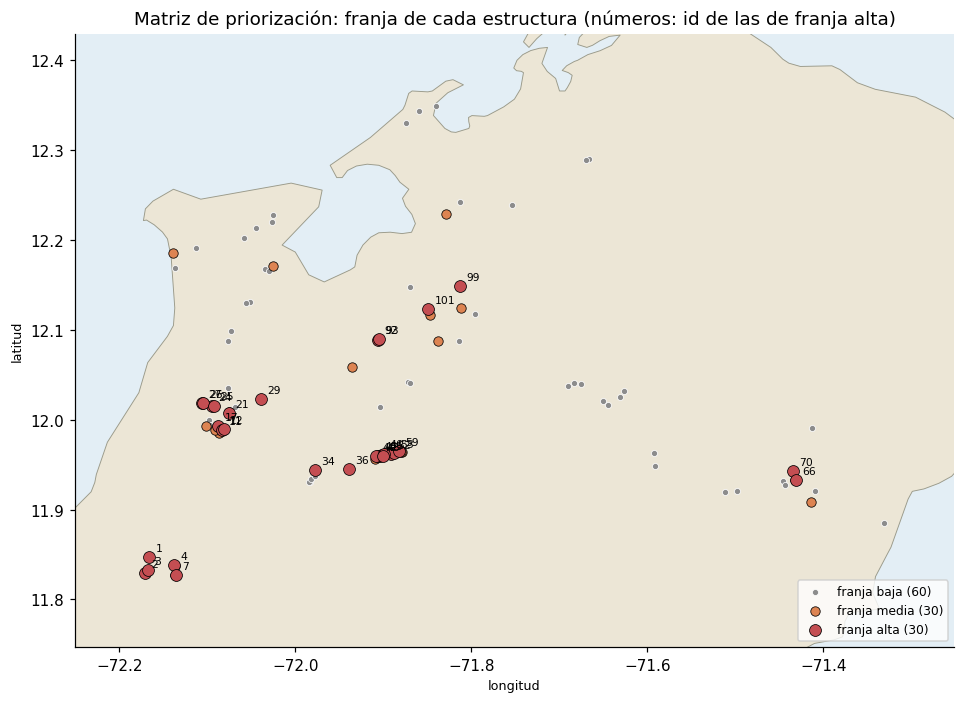

In [13]:
fig, ax = plt.subplots(figsize=(11, 6.5))
fondo_guajira(ax, matriz["lat"], matriz["lon"])
for f in ["baja", "media", "alta"]:
    sub = matriz[matriz["franja"] == f]
    ax.scatter(sub["lon"], sub["lat"], s={"alta": 60, "media": 38, "baja": 16}[f], color=COLOR_FRANJA[f], edgecolor="black" if f != "baja" else "white",
               lw=0.5, label=f"franja {f} ({len(sub)})", zorder=3)
for _, f in matriz[matriz["franja"] == "alta"].iterrows():
    ax.annotate(int(f["id"]), (f["lon"], f["lat"]), textcoords="offset points", xytext=(4, 4), fontsize=7, zorder=4)
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Matriz de priorización: franja de cada estructura (números: id de las de franja alta)")
fig.tight_layout()
plt.show()

Las estructuras de la franja alta no están repartidas al azar. Se concentran en pocos campos: el extremo suroeste (ids 1, 2, 3, 4 y 7), un grupo alrededor de 12,0° N y 72,09° O (11, 12, 17, 21, 24 a 27 y 29), una alineación en torno a 11,96° N y 71,90° O (34, 36, 40, 42, 43, 45, 46, 52, 53 y 59), los pares 92 y 93 al centro, 99 y 101 hacia el norte, y 66 y 70 al este. En el norte de la península y alrededor de 71,65° O solo hay estructuras de las franjas media y baja. Para planear una campaña, estos campos son unidades más útiles que las estructuras sueltas.

### Estructuras vecinas

En la sección 5.3 aparecieron pares de estructuras del inventario cuyas huellas se solapan: están a pocas decenas o cientos de metros y cada una aparece, al menos en parte, en la foto de la otra. Comparar sus resultados dice qué tan estable es P(H2) frente al encuadre: si dos fotos que comparten buena parte del terreno dan valores muy distintos, la cifra de una estructura aislada debe leerse con más cautela.

In [14]:
por_id = matriz.set_index("id")
vecinas = pd.DataFrame([{"id": a, "id vecina": b, "distancia (m)": round(d), "P(H2)": por_id.at[a, "P(H2)"], "P(H2) vecina": por_id.at[b, "P(H2)"],
                         "franja": por_id.at[a, "franja"], "franja vecina": por_id.at[b, "franja"]} for (a, b), d in zip(pares, d_pares)])
display(vecinas.round(3))
print(f"Pares en la misma franja: {(vecinas['franja'] == vecinas['franja vecina']).sum()} de {len(vecinas)}. "
      f"Diferencia mediana de P(H2) dentro de un par: {(vecinas['P(H2)'] - vecinas['P(H2) vecina']).abs().median():.2f}.")

,id,id vecina,distancia (m),P(H2),P(H2) vecina,franja,franja vecina
0,4,5,98,0.973,0.699,alta,media
1,6,7,51,0.630,0.846,media,alta
2,9,10,52,0.000,0.000,baja,baja
3,11,14,169,0.915,0.355,alta,media
4,12,13,106,0.775,0.452,alta,media
5,21,22,134,0.770,0.236,alta,media
6,26,27,70,0.830,0.857,alta,alta
7,30,31,122,0.033,0.050,baja,baja
8,35,36,113,0.075,0.958,baja,alta
9,38,39,316,0.015,0.264,baja,media


Pares en la misma franja: 11 de 26. Diferencia mediana de P(H2) dentro de un par: 0.27.


Solo 11 de los 26 pares quedan en la misma franja, y dentro de un par P(H2) difiere en 0,27 en mediana. Casi todos los cambios son entre franjas contiguas: 11 pares se reparten entre alta y media y 3 entre media y baja. Solo el par 35–36 salta de la baja a la alta (0,08 y 0,96). En los cuatro pares que mezclan zoom 19 y 20 (4–5, 12–13, 30–31 y 35–36), la estructura de zoom 20 tiene siempre la P(H2) más baja, como se vio en la sección 5.5. El caso más llamativo es el de las estructuras 58 y 59: sus centros están a 35 m, tienen el mismo zoom y las dos fotos muestran casi el mismo terreno, pero su P(H2) es 0,31 y 0,95.

P(H2) depende bastante del encuadre: mover la foto unas decenas de metros puede cambiar la franja. Para el trabajo de campo conviene tratar cada grupo de vecinas como una unidad, con la prioridad de su mejor miembro. Así, la 56, la 57 y la 58, de la franja media, se visitarían junto con la 59, de la franja alta.

## 5.7 Qué mira el modelo en las estructuras prioritarias

Antes de llevar una estructura a campo conviene saber en qué se apoyó el modelo para darle una P(H2) alta. Para eso se usa **Grad-CAM**, el mapa de calor de la sección 4.7: colorea la imagen según cuánto pesó cada zona en la decisión (rojo mucho, azul poco). Allí se calculaba para la clase predicha; aquí se calcula siempre **para H2**, porque lo que interesa es qué zonas empujan la P(H2) hacia arriba. El mapa sale de una cuadrícula de 7 × 7 posiciones, así que indica zonas, no contornos.

Como resumen numérico se usa la misma **razón de concentración** de la sección 4.7: la fracción de la atención que cae dentro del disco central (el círculo punteado, de diámetro igual al 60 % del lado) dividida entre la fracción del área que ocupa ese disco. Vale 1 si la atención se reparte por igual y es mayor cuanto más se concentra en el centro, donde se capturó la estructura. En el notebook 4, la mediana de las H2 de validación fue 1,06: el modelo reconoce las H2 en buena parte por el paisaje que las rodea. Una razón alta indica que la P(H2) de esa estructura se apoya en la depresión misma; una cercana a 1 o menor, que se apoya en el entorno.

Se muestran las 12 estructuras de mayor P(H2) y, debajo, algunas de las franjas media y baja tomadas a lo largo del orden, para comparar. Cada imagen lleva encima su puesto en la matriz (`#`), su `id` en el inventario, su P(H2) y la clase predicha. Así, «#48 · id 61 / P(H2) 0.354 · Jaguey» es la estructura 61, puesto 48 de 120, con P(H2) de 0,354 y predicha como Jagüey porque su P(Jagüey) es todavía mayor. P(H2) va con tres decimales para que se pueda comparar con los cortes (0,710 y 0,092).

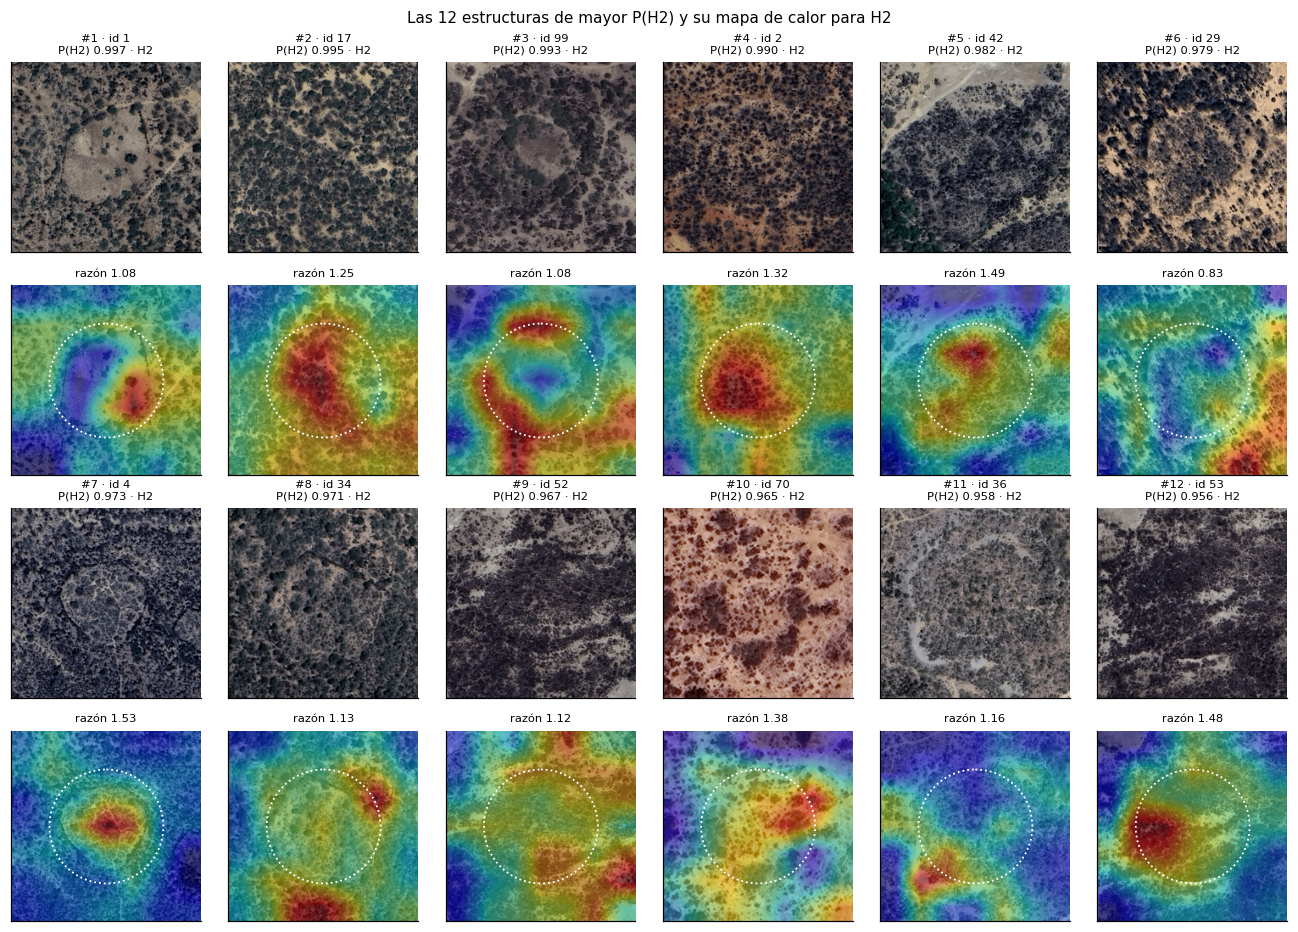

Razón de concentración mediana de estas 12: 1.20  (H2 de validación en el notebook 4: 1,06).


In [15]:
ids_top = matriz["id"].head(N_MAPAS_CALOR).astype(int).tolist()
cams = gradcam(MODELO, [IMAGENES[i] for i in ids_top], IDX["H2"])
yy, xx = np.mgrid[:IMGSZ, :IMGSZ]
DISCO = ((xx - IMGSZ / 2) ** 2 + (yy - IMGSZ / 2) ** 2) <= (R_CENTRO * IMGSZ) ** 2
razon = {i: float(c[DISCO].sum() / max(c.sum(), 1e-12) / DISCO.mean()) for i, c in zip(ids_top, cams)}

def dibujar(ax, im, cam=None, titulo=None):
    ax.imshow(im.resize((IMGSZ, IMGSZ)))
    if cam is not None:
        ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.add_patch(plt.Circle((IMGSZ / 2, IMGSZ / 2), R_CENTRO * IMGSZ, fill=False, ec="white", ls=":", lw=1.2))
    ax.set_xticks([]); ax.set_yticks([])
    if titulo:
        ax.set_title(titulo, fontsize=7.5)

columnas = 6
fig, ejes = plt.subplots(2 * int(np.ceil(N_MAPAS_CALOR / columnas)), columnas, figsize=(2.0 * columnas, 4.3 * np.ceil(N_MAPAS_CALOR / columnas)))
for k, (i, cam) in enumerate(zip(ids_top, cams)):
    fila = matriz[matriz["id"] == i].iloc[0]
    f, c = 2 * (k // columnas), k % columnas
    dibujar(ejes[f, c], IMAGENES[i], titulo=f"#{fila['prioridad']} · id {i}\nP(H2) {fila['P(H2)']:.3f} · {fila['clase predicha']}")
    dibujar(ejes[f + 1, c], IMAGENES[i], cam, titulo=f"razón {razon[i]:.2f}")
fig.suptitle(f"Las {N_MAPAS_CALOR} estructuras de mayor P(H2) y su mapa de calor para H2", fontsize=10)
fig.tight_layout()
plt.show()
print(f"Razón de concentración mediana de estas {N_MAPAS_CALOR}: {np.median(list(razon.values())):.2f}  (H2 de validación en el notebook 4: 1,06).")

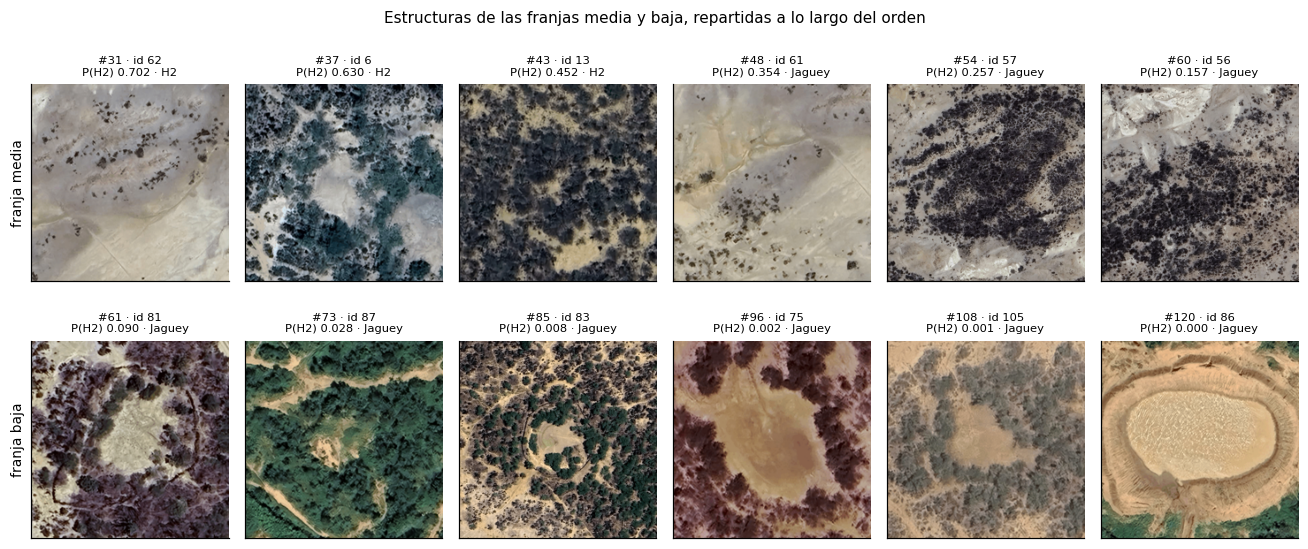

In [16]:
muestras = {}
for f in ("media", "baja"):
    sub = matriz[matriz["franja"] == f]
    muestras[f] = sub.iloc[np.unique(np.linspace(0, len(sub) - 1, min(6, len(sub))).round().astype(int))]
fig, ejes = plt.subplots(2, 6, figsize=(12, 5.4))
for r, (f, sub) in enumerate(muestras.items()):
    for c in range(6):
        if c < len(sub):
            fila = sub.iloc[c]
            dibujar(ejes[r, c], IMAGENES[int(fila["id"])], titulo=f"#{fila['prioridad']} · id {int(fila['id'])}\nP(H2) {fila['P(H2)']:.3f} · {fila['clase predicha']}")
        else:
            ejes[r, c].axis("off")
    ejes[r, 0].set_ylabel(f"franja {f}", fontsize=9)
fig.suptitle("Estructuras de las franjas media y baja, repartidas a lo largo del orden", fontsize=10)
fig.tight_layout()
plt.show()

Las 12 estructuras de mayor prioridad tienen P(H2) entre 0,956 y 0,997. A la vista, casi todas son claros o depresiones redondeadas dentro del matorral seco, con menos vegetación en el interior y a menudo un anillo de vegetación más densa alrededor (ids 1, 99, 29, 4 y 34). Es el aspecto de muchas H2 de entrenamiento.

La razón de concentración va de 0,83 a 1,53, con mediana 1,20, por encima de la de las H2 de validación (1,06). En 6 de las 12 (ids 17, 2, 42, 4, 70 y 53) es de 1,25 o más y el mapa se enciende sobre la depresión: en esas, la P(H2) se apoya sobre todo en la estructura. En las demás la atención va al borde o fuera del disco: en la 1 cae sobre el borde derecho del claro, en la 99 sobre un arco del anillo y en la 29, la 34 y la 36 en buena parte fuera del círculo. Estas últimas, aun con P(H2) alta, deben su prioridad en parte al entorno. Como se vio en la sección 4.7 (notebook 4), la razón indica dónde se apoya el modelo, no si acierta.

En la segunda figura, la fila de la franja media muestra la zona de duda. De la #31 a la #48 todas se capturaron con zoom 20, y las tres primeras siguen predichas como H2. La #31 (id 62) se queda a ocho milésimas del corte de la franja alta. En la fila de la franja baja, la estructura de menor prioridad (#120, id 86) es un vaso excavado con un borde de tierra levantado, el aspecto típico de un jagüey. Pero la franja baja no se compone solo de reservorios evidentes. La #61 (id 81), que queda justo por debajo del corte inferior, y la #85 (id 83) muestran claros redondeados no muy distintos de los de la franja alta. Estar en la franja baja no equivale a quedar descartada.

## Resumen

- **Modelo:** el YOLOv8n-cls congelado en el notebook 4, con su huella verificada contra la registrada al evaluar el holdout, la temperatura T = 1,03 y los cortes de las franjas fijados antes de ver estas imágenes. Una sola pasada, sin ningún ajuste.
- **Inventario:** 120 imágenes íntegras, ninguna repetida ni del entrenamiento. Por zoom (19–20) y por lugar se parecen a los Jagüeyes de entrenamiento y no a las H2.
- **Independencia:** solo la estructura 37 comparte terreno con una imagen de entrenamiento (el Jagüey 584) y queda marcada. Hay 26 pares de estructuras vecinas con huellas solapadas dentro del inventario.
- **Franjas:** 30 alta, 30 media y 60 baja. Las 30 de la franja alta se predicen como H2. En total, 63 estructuras se predicen como Jagüey y 43 como H2. La clase alternativa dominante es Jagüey (87), seguida de Impact crater (19).
- **Zoom:** 30 de las 41 estructuras de zoom 20 quedan en la franja baja (P(H2) mediana de 0,016, frente a 0,394 con zoom 19).
- **Estabilidad:** solo 11 de 26 pares de vecinas coinciden en franja, aunque solo uno salta de la baja a la alta.
- **Mapas de calor:** en 6 de las 12 estructuras de mayor prioridad la atención se concentra sobre la depresión. La razón mediana es 1,20, frente a 1,06 en las H2 de validación.
- **Archivos:** `salidas/aplicacion_predicciones.csv`, `salidas/matriz_priorizacion.csv` y `salidas/matriz_priorizacion.geojson`.

**Qué se puede afirmar.** La matriz es un orden de prioridad para orientar el trabajo de campo, no una clasificación. Que una estructura esté en la franja alta significa que el modelo le asigna mucha más afinidad con H2 que al resto del inventario, no que sea una SCD. Las 30 de la franja alta, agrupadas en unos pocos campos, son las primeras candidatas a visitar. La franja media es imprescindible: en el ensayo de región nueva (sección 4.9) reunió casi la mitad de las H2 que el modelo sí aprende a reconocer. Dentro de la franja baja, las estructuras de zoom 20 o 21 y las que tienen una vecina en una franja más alta merecen una revisión visual antes de descartarlas. Ninguna cifra de este notebook sustituye la verificación en campo.